# Test: mark significant or non-significant cells?

Same data and test as `forcing_maps.ipynb` (9 paired yearly differences, cell-wise t-test, Benjamini–Hochberg FDR α = 0.10 over the cells ≥ 45°N). Only the way the result is drawn changes:

Ocean is **not** faded (ocean signals matter here).

| Row | Marked cells | Style |
|---|---|---|
| A | significant | dots (current figures) |
| B | non-significant | diagonal hatching `////`, dim grey, lw 0.4 |
| C | non-significant | denser hatching `/////`, dim grey, lw 0.3 |
| D | non-significant | faded: white layer, alpha 0.5, no outline |
| E | non-significant | faded: white layer, alpha 0.7, no outline |

**IPCC conventions** (from memory, not re-checked): AR5 put stippling on robust/significant cells and hatching on non-significant ones. AR6 (WGI Atlas, Cross-Chapter Box Atlas.1) leaves robust signals **unmarked**: diagonal lines = no robust signal, crossed lines = conflicting signals. The AR6 observed-trend maps put crosses on non-significant trends.
**Caveat:** AR6 "robustness" = agreement between models + a variability threshold. Here the test is about interannual variability in a single model.

Non-significant = not significant **and** finite p **and** ≥ 45°N (so NaN cells and the untested region are not marked).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # repo src/, no pip install needed

import numpy as np
import xarray as xr
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from boreal_forest_expansion.plotting.style import set_default_style
from boreal_forest_expansion.plotting import forcing_maps as fm
from boreal_forest_expansion.analysis.stats import cellwise_pvalue, fdr_mask

set_default_style()
START_YEAR, END_YEAR, LAT_MIN, FDR_ALPHA = 2001, 2009, 45, 0.10
PANEL_KEYS = ["total", "bvoc_total", "bvoc_cloud"]
FIGDIR = Path.cwd().parent / "results" / "figures" / "tests"

def pairs_for(exp):
    return fm.BVOC_PAIRS[exp]

In [2]:
def hatch_nonsig(ax, mask, hatch="///", color="dimgrey", lw=0.4, zorder=4):
    """Diagonal lines over the True cells of `mask` (AR6 look); thin, grey lines."""
    data, lon_c = add_cyclic_point(mask.astype(float).values, coord=mask["lon"].values)
    cs = ax.contourf(lon_c, mask["lat"].values, np.where(data > 0.5, 1.0, np.nan), levels=[0.5, 1.5],
                     colors="none", hatches=[hatch], transform=ccrs.PlateCarree(), zorder=zorder)
    cs.set_edgecolor(color)
    cs.set_linewidth(0.0)
    cs.set_hatch_linewidth(lw)


def fade_nonsig(ax, mask, alpha=0.6, color="white", zorder=1.5):
    """Fade the True cells of `mask` with a semi-transparent layer on the data grid (no outline).
    zorder 1.5: above the data (1), below the coastlines (3)."""
    layer = xr.ones_like(mask, dtype=float).where(mask)
    layer.plot.pcolormesh(ax=ax, x="lon", y="lat", transform=ccrs.PlateCarree(),
                          cmap=ListedColormap([color]), alpha=alpha, add_colorbar=False, add_labels=False, zorder=zorder)


def panel_masks(panel, pairs):
    """Yearly differences, significant mask and non-significant mask (both within >= LAT_MIN)."""
    d = fm.yearly_difference(pairs[panel.case1_role], pairs[panel.case2_role], panel.variable_class,
                             panel.variable, START_YEAR, END_YEAR, panel.component)
    p = cellwise_pvalue(d)
    region = d["lat"] >= LAT_MIN
    sig = fdr_mask(p, alpha=FDR_ALPHA, within=region)
    nonsig = (~sig) & np.isfinite(p) & region
    n_tested = int((np.isfinite(p) & region).sum())
    assert int(sig.sum()) + int(nonsig.sum()) == n_tested
    return d, sig, nonsig, n_tested


# (row label, drawing function on the non-significant mask); row A = current figures for reference
ROWS = [
    ("A: significant, dots (current)", None),
    ("B: hatching //// dim grey, lw 0.4", lambda ax, m: hatch_nonsig(ax, m, "////", "dimgrey", 0.4)),
    ("C: hatching ///// dim grey, lw 0.3", lambda ax, m: hatch_nonsig(ax, m, "/////", "dimgrey", 0.3)),
    ("D: faded (white, alpha 0.5)", lambda ax, m: fade_nonsig(ax, m, 0.5)),
    ("E: faded (white, alpha 0.7)", lambda ax, m: fade_nonsig(ax, m, 0.7)),
]


def make_test_figure(exp, band="NET"):
    pairs = pairs_for(exp)
    panels = {p.key: p for p in fm.forcing_panels(band)}
    fig, axes = plt.subplots(len(ROWS), len(PANEL_KEYS), figsize=(11, 18.5),
                             subplot_kw={"projection": ccrs.Orthographic(0, 90)}, constrained_layout=True)
    print(f"{exp} {band}  (fBVOC alias: {pairs['fbvoc']})")
    print(f"{'panel':<12}{'cells tested':>14}{'significant':>13}{'%':>7}")
    for j, key in enumerate(PANEL_KEYS):
        panel = panels[key]
        d, sig, nonsig, n = panel_masks(panel, pairs)
        print(f"{key:<12}{n:>14}{int(sig.sum()):>13}{100 * int(sig.sum()) / n:>7.1f}")
        m, half = fm.regional_mean_interval(d, lat_min=LAT_MIN)
        da = d.mean("year")
        for i, (label, draw) in enumerate(ROWS):
            ax = axes[i, j]
            fm.plot_single_boreal_panel(
                ax=ax, da=da, title=f"{panel.title}\n{label}", units=panel.units,
                vmax=panel.vmax or fm.symmetric_vmax(da), extent_lat=LAT_MIN, mean_lat_min=LAT_MIN,
                add_cbar=(i == len(ROWS) - 1), cbar_label=f"{panel.long_label}\n[{panel.units}]",
                shade_ocean=False,
                sig=sig if draw is None else None, sig_style="dots",
                mean_text=f"mean ≥{LAT_MIN}°N: {fm._format_interval(m, half)}")
            if draw is not None and bool(nonsig.any()):
                draw(ax, nonsig)
    fig.suptitle(f"{exp}: significance marking test ({band}, {START_YEAR}–{END_YEAR})",
                 fontsize=13, fontweight="bold")
    FIGDIR.mkdir(parents=True, exist_ok=True)
    path = FIGDIR / f"significance_marking_{exp}_{band}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print(f"Saved {path}")
    return fig, axes

## Present day

PD NET  (fBVOC alias: LCC_PD_fBVOC)
panel         cells tested  significant      %
total                 3456          844   24.4
bvoc_total            3456            1    0.0


findfont: Failed to find font weight semibold, now using 700.


bvoc_cloud            3456            0    0.0


findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.


Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/tests/significance_marking_PD_NET.png


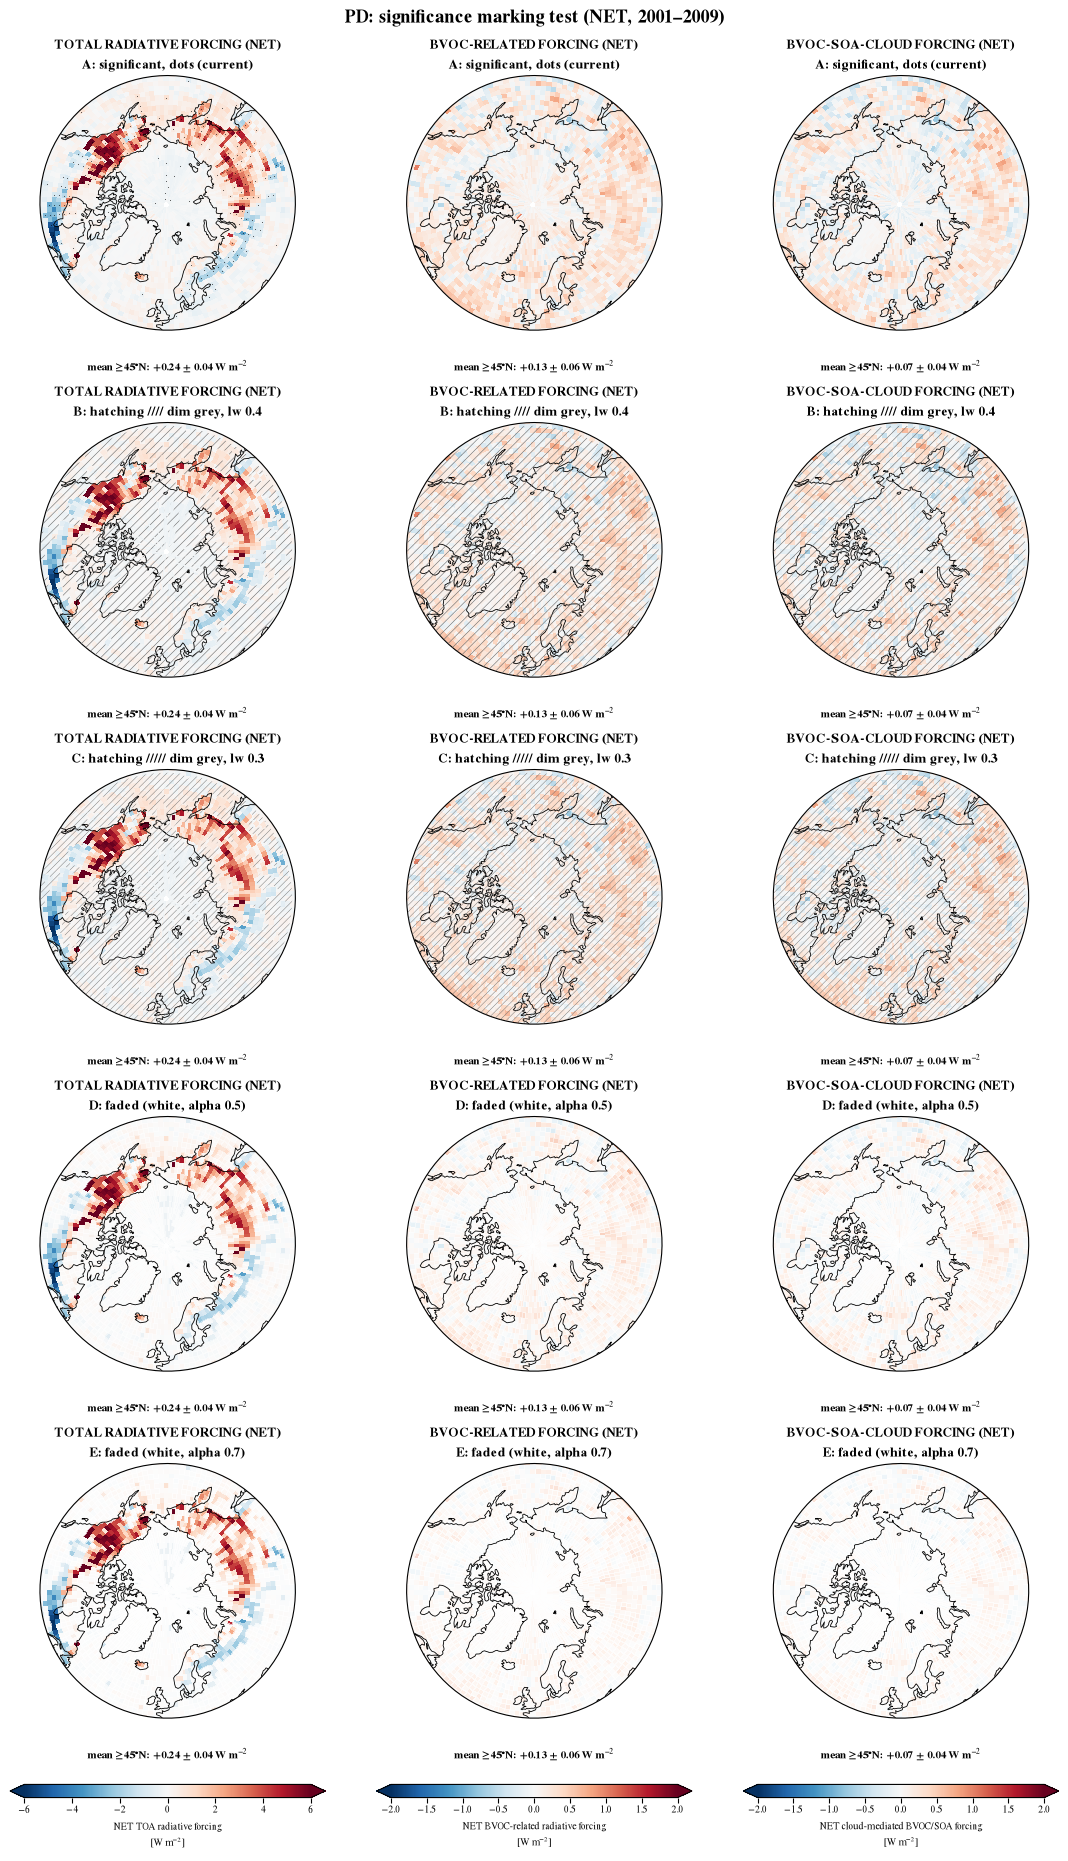

In [3]:
fig, axes = make_test_figure("PD")

## Future

FUT NET  (fBVOC alias: LCC_FUT_fBVOC)
panel         cells tested  significant      %
total                 3456          978   28.3
bvoc_total            3456         3068   88.8
bvoc_cloud            3456         3256   94.2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/tests/significance_marking_FUT_NET.png


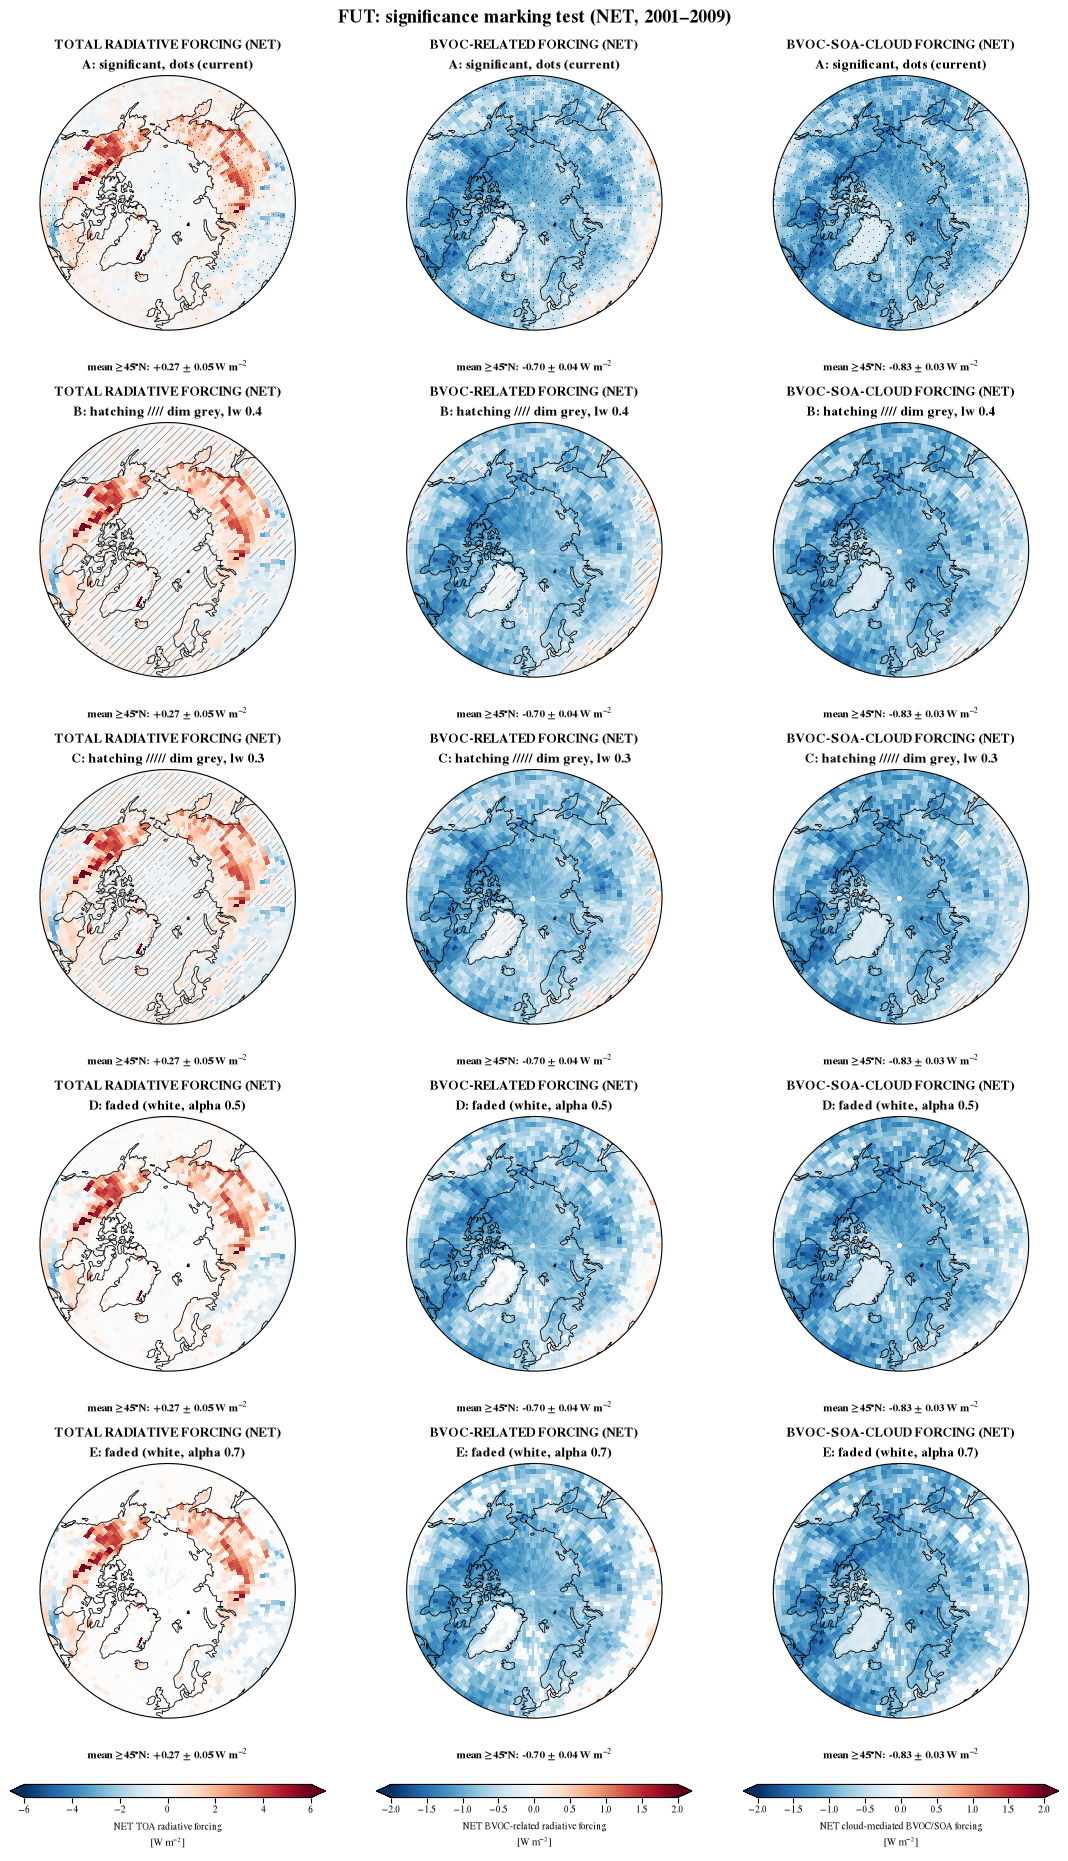

In [4]:
fig, axes = make_test_figure("FUT")